# Downstream analysis: drift error E and zones

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

models_folder  = "*/Models"
results_folder = "*/Analysis"
os.makedirs(results_folder, exist_ok=True)

# model name: (folder, end of the file name)
models = {
    "Chronos2":    ("Chronos2", "chronos"),
    "ChronosBOLT": ("ChronosBOLT", "chronos_bolt"),
    "Moirai":      ("Moirai", "moirai"),
    "TimesFM":     ("TimesFM", "times_fm"),
}
context_lengths = [32, 64, 128, 256, 512]
walk_column = "walk_id"      # the column that says which walk a row belongs to

# read all prediction files into one table
tables = []
for model_name, (folder, file_end) in models.items():
    for L in context_lengths:
        file_path = f"{models_folder}/{folder}/predicitons_{L}_{file_end}.csv"
        predictions = pd.read_csv(file_path)
        predictions["model"] = model_name
        predictions["L"] = L
        tables.append(predictions)

data = pd.concat(tables, ignore_index=True)
data["snr"] = data["snr"].round(6)       # remove tiny float differences

# the forecasts start at the last context point, so the naive forecast is 0
print("naive is 0 everywhere:", np.allclose(data["naive"], 0))

# the plug-in forecast is horizon * context drift, so the context drift is plugin / horizon
data["context_drift"] = data["plugin"] / data["horizon"]

cell_columns = ["model", "L", "snr", "horizon"]    # one cell = all walks with the same settings
model_names = list(models)
print(data.shape)
data.head()

naive is 0 everywhere: True
(64000000, 22)


,Unnamed: 0,walk_id,snr,seed,sigma,mu,context_len,horizon,model,checkpoint,...,naive,plugin,conditional,se_model,se_naive,se_plugin,se_conditional,L,num_samples,context_drift
0,0,snr0.01_seed0,0.01,0,1.0,0.01,32,1,Chronos2,chronos-2-amazon,...,0.0,-0.023217,0.01,0.004846,0.023383,0.031022,0.020424,32,NaN,-0.023217
1,1,snr0.01_seed0,0.01,0,1.0,0.01,32,2,Chronos2,chronos-2-amazon,...,0.0,-0.046434,0.02,0.244420,0.145195,0.111964,0.160836,32,NaN,-0.023217
2,2,snr0.01_seed0,0.01,0,1.0,0.01,32,3,Chronos2,chronos-2-amazon,...,0.0,-0.069650,0.03,0.367308,0.254516,0.189090,0.285686,32,NaN,-0.023217
3,3,snr0.01_seed0,0.01,0,1.0,0.01,32,4,Chronos2,chronos-2-amazon,...,0.0,-0.092867,0.04,0.537184,0.645413,0.803252,0.582743,32,NaN,-0.023217
4,4,snr0.01_seed0,0.01,0,1.0,0.01,32,5,Chronos2,chronos-2-amazon,...,0.0,-0.116084,0.05,0.042312,0.023853,0.001471,0.041797,32,NaN,-0.023217


# Mean and Median table

In [2]:
# drift error E = |context drift - forecast drift| / |context drift|
# 0 = drift kept exactly, 1 = flat forecast (or twice the drift), above 1 is worse
forecast_drift = data["forecast"] / data["horizon"]
data["E"] = (data["context_drift"] - forecast_drift).abs() / data["context_drift"].abs()
data.loc[data["context_drift"] == 0, "E"] = np.nan

E_table = data.groupby(cell_columns)["E"].agg(E_mean="mean", E_median="median").reset_index()

# zones: 1 safe, 2 caution, 3 unsafe, 0 undefined
eps_crit = 0.5
gamma = 1.5
safe_limit = eps_crit / gamma

E_table["zone_mean"] = 0
E_table.loc[E_table["E_mean"] <= safe_limit, "zone_mean"] = 1
E_table.loc[(E_table["E_mean"] > safe_limit) & (E_table["E_mean"] <= eps_crit), "zone_mean"] = 2
E_table.loc[E_table["E_mean"] > eps_crit, "zone_mean"] = 3

E_table["zone_median"] = 0
E_table.loc[E_table["E_median"] <= safe_limit, "zone_median"] = 1
E_table.loc[(E_table["E_median"] > safe_limit) & (E_table["E_median"] <= eps_crit), "zone_median"] = 2
E_table.loc[E_table["E_median"] > eps_crit, "zone_median"] = 3

E_table.to_csv(f"{results_folder}/downstream_E.csv", index=False)
E_table

,model,L,snr,horizon,E_mean,E_median,zone_mean,zone_median
0,Chronos2,32,0.01,1,6.294591,1.972793,3,3
1,Chronos2,32,0.01,2,5.907775,1.630140,3,3
2,Chronos2,32,0.01,3,5.187361,1.505976,3,3
3,Chronos2,32,0.01,4,4.740654,1.454364,3,3
4,Chronos2,32,0.01,5,4.375626,1.451386,3,3
...,...,...,...,...,...,...,...,...
639995,TimesFM,512,5.00,252,0.043186,0.041734,1,1
639996,TimesFM,512,5.00,253,0.043332,0.041969,1,1
639997,TimesFM,512,5.00,254,0.041185,0.039643,1,1
639998,TimesFM,512,5.00,255,0.040867,0.039390,1,1


# Mean plot

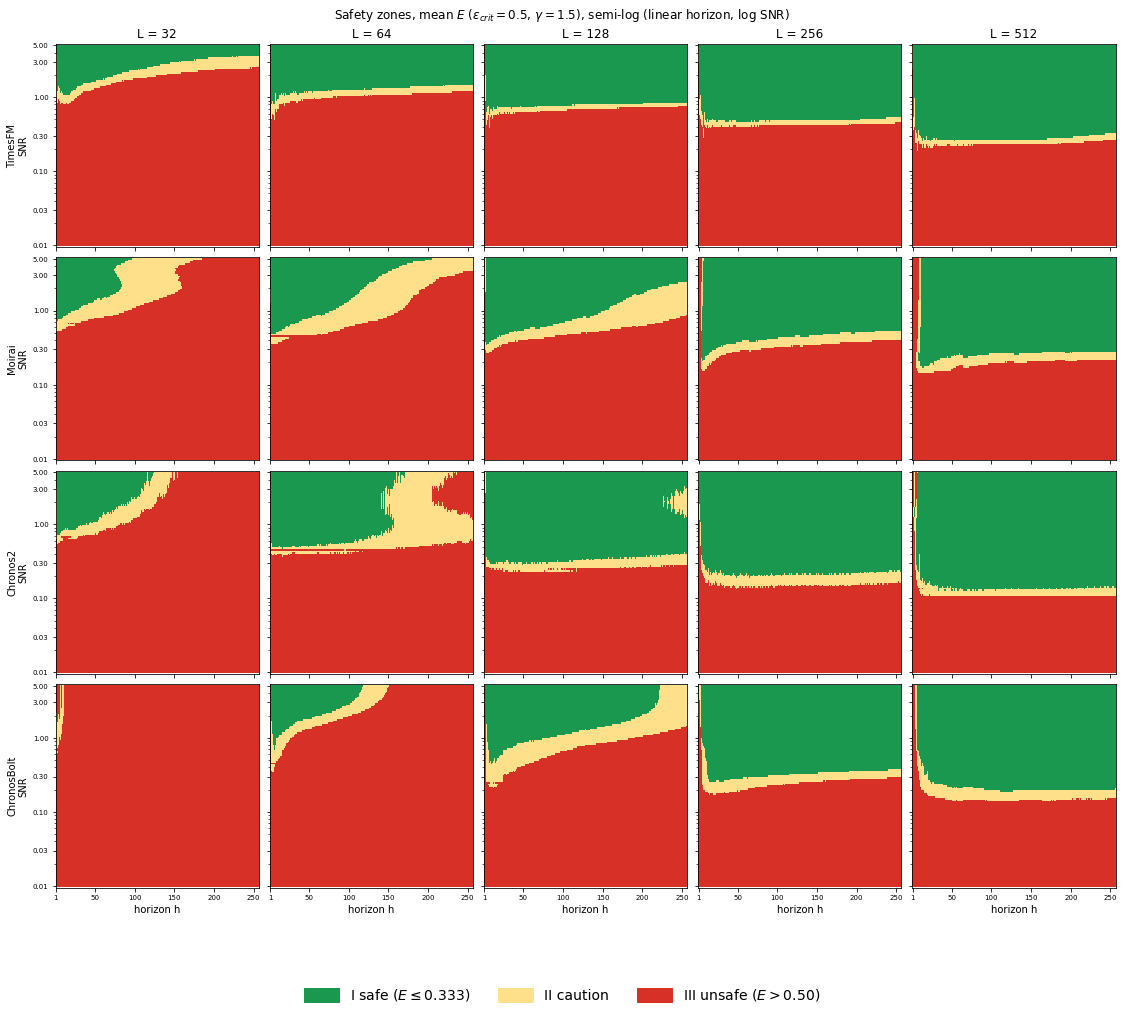

In [4]:
# Mean plot, semi-log (linear horizon, log SNR)
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.ticker import ScalarFormatter

# same order and names as the old figure
model_order = ["TimesFM", "Moirai", "Chronos2", "ChronosBOLT"]
model_labels = {"TimesFM": "TimesFM", "Moirai": "Moirai", "Chronos2": "Chronos2", "ChronosBOLT": "ChronosBolt"}
legend_fontsize = 14

zone_colors = ["#bdbdbd", "#1a9850", "#fee08b", "#d73027"]        # 0 undefined, 1 safe, 2 caution, 3 unsafe
zone_names = ["undefined", f"I safe ($E\\leq{safe_limit:.3f}$)", "II caution", f"III unsafe ($E>{eps_crit:.2f}$)"]
colormap = ListedColormap(zone_colors)
color_steps = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], 4)

# the same SNR and horizon grid in every panel
snr_values = np.array(sorted(E_table["snr"].unique()))
horizon_values = np.array(sorted(E_table["horizon"].unique()))

fig, axes = plt.subplots(len(model_order), len(context_lengths),
                         figsize=(3.1 * len(context_lengths), 3.1 * len(model_order)),
                         sharex=True, sharey=True, constrained_layout=True, squeeze=False)
zones_used = []

for row, model_name in enumerate(model_order):
    for col, L in enumerate(context_lengths):
        part = E_table[(E_table["model"] == model_name) & (E_table["L"] == L)]
        zone_grid = part.pivot(index="snr", columns="horizon", values="zone_mean")
        zone_grid = zone_grid.reindex(index=snr_values, columns=horizon_values).to_numpy().astype(float)
        zones_used += list(np.unique(zone_grid[np.isfinite(zone_grid)]))

        ax = axes[row, col]
        ax.pcolormesh(horizon_values, snr_values, np.ma.masked_invalid(zone_grid),
                      cmap=colormap, norm=color_steps, shading="nearest")
        ax.set_xscale("linear")
        ax.set_yscale("log")
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.yaxis.set_major_formatter(ScalarFormatter())
        ax.set_xticks([1, 50, 100, 150, 200, 250])
        ax.set_yticks([0.01, 0.03, 0.1, 0.3, 1, 3, 5])
        ax.set_xlim(horizon_values.min() - 0.5, horizon_values.max() + 0.5)
        ax.set_ylim(snr_values.min() * 0.95, snr_values.max() * 1.05)
        ax.tick_params(labelsize=7)
        if row == 0:
            ax.set_title(f"L = {L}")
        if col == 0:
            ax.set_ylabel(f"{model_labels[model_name]}\nSNR")
        if row == len(model_order) - 1:
            ax.set_xlabel("horizon h")

fig.suptitle(f"Safety zones, mean $E$ ($\\epsilon_{{crit}}={eps_crit}$, $\\gamma={gamma}$), "
             f"semi-log (linear horizon, log SNR)", y=1.02)

# legend below the figure, only with the zones that occur
legend_boxes = []
for zone in range(4):
    if zone in zones_used:
        legend_boxes.append(plt.Rectangle((0, 0), 1, 1, color=zone_colors[zone], label=zone_names[zone]))
fig.legend(handles=legend_boxes, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.11),
           fontsize=legend_fontsize, handlelength=2.5, handleheight=1.2, columnspacing=2.0)

fig.savefig(f"{results_folder}/fig1_zones_mean_semilog.png", dpi=200, bbox_inches="tight")
plt.show()

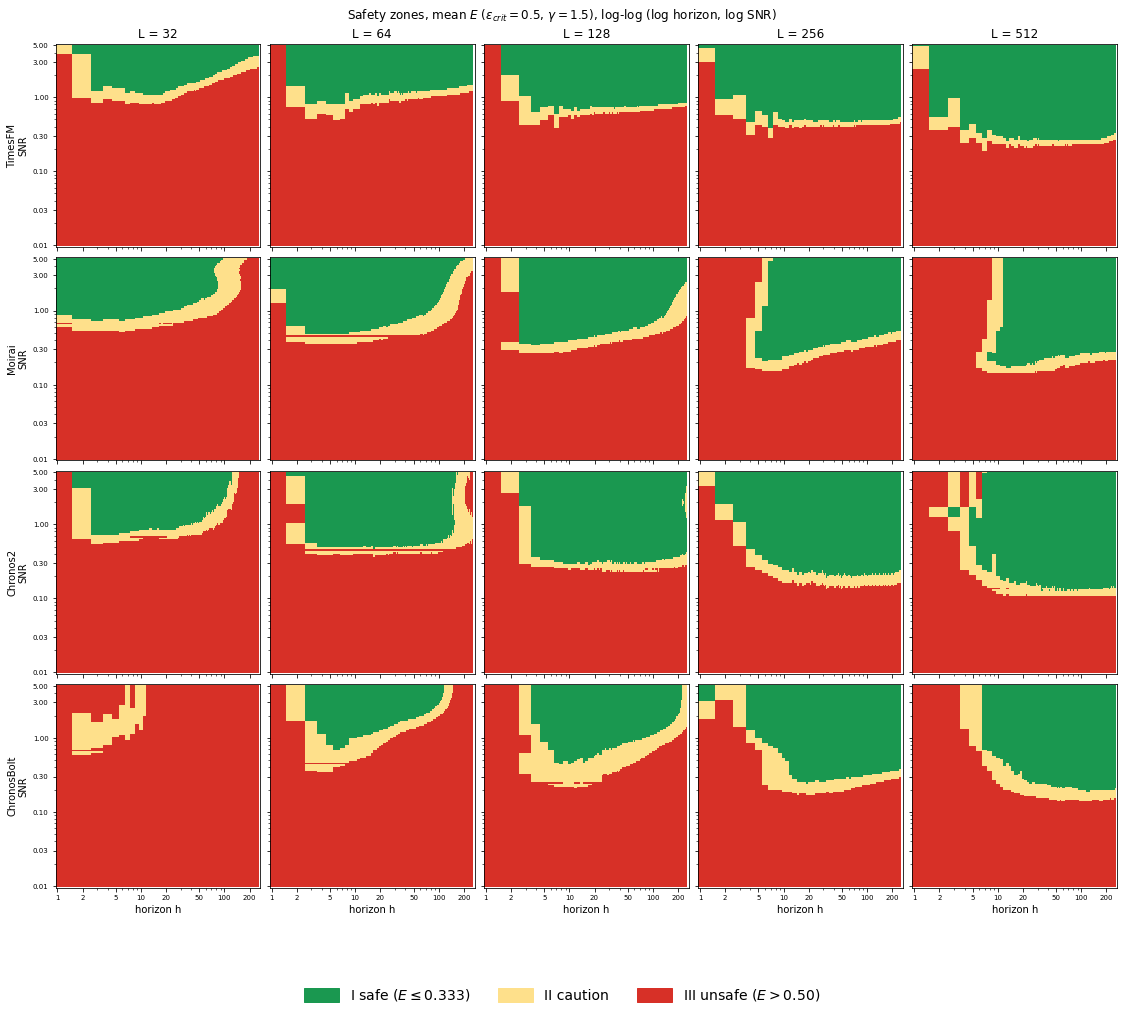

In [5]:
# Mean plot, log-log (log horizon, log SNR)
fig, axes = plt.subplots(len(model_order), len(context_lengths),
                         figsize=(3.1 * len(context_lengths), 3.1 * len(model_order)),
                         sharex=True, sharey=True, constrained_layout=True, squeeze=False)
zones_used = []

for row, model_name in enumerate(model_order):
    for col, L in enumerate(context_lengths):
        part = E_table[(E_table["model"] == model_name) & (E_table["L"] == L)]
        zone_grid = part.pivot(index="snr", columns="horizon", values="zone_mean")
        zone_grid = zone_grid.reindex(index=snr_values, columns=horizon_values).to_numpy().astype(float)
        zones_used += list(np.unique(zone_grid[np.isfinite(zone_grid)]))

        ax = axes[row, col]
        ax.pcolormesh(horizon_values, snr_values, np.ma.masked_invalid(zone_grid),
                      cmap=colormap, norm=color_steps, shading="nearest")
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.yaxis.set_major_formatter(ScalarFormatter())
        ax.set_xticks([1, 2, 5, 10, 20, 50, 100, 200])
        ax.set_yticks([0.01, 0.03, 0.1, 0.3, 1, 3, 5])
        ax.set_xlim(horizon_values.min() * 0.95, horizon_values.max() * 1.05)
        ax.set_ylim(snr_values.min() * 0.95, snr_values.max() * 1.05)
        ax.tick_params(labelsize=7)
        if row == 0:
            ax.set_title(f"L = {L}")
        if col == 0:
            ax.set_ylabel(f"{model_labels[model_name]}\nSNR")
        if row == len(model_order) - 1:
            ax.set_xlabel("horizon h")

fig.suptitle(f"Safety zones, mean $E$ ($\\epsilon_{{crit}}={eps_crit}$, $\\gamma={gamma}$), "
             f"log-log (log horizon, log SNR)", y=1.02)

# legend below the figure, only with the zones that occur
legend_boxes = []
for zone in range(4):
    if zone in zones_used:
        legend_boxes.append(plt.Rectangle((0, 0), 1, 1, color=zone_colors[zone], label=zone_names[zone]))
fig.legend(handles=legend_boxes, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.11),
           fontsize=legend_fontsize, handlelength=2.5, handleheight=1.2, columnspacing=2.0)

fig.savefig(f"{results_folder}/fig1_zones_mean_loglog.png", dpi=200, bbox_inches="tight")
plt.show()

# Median plot

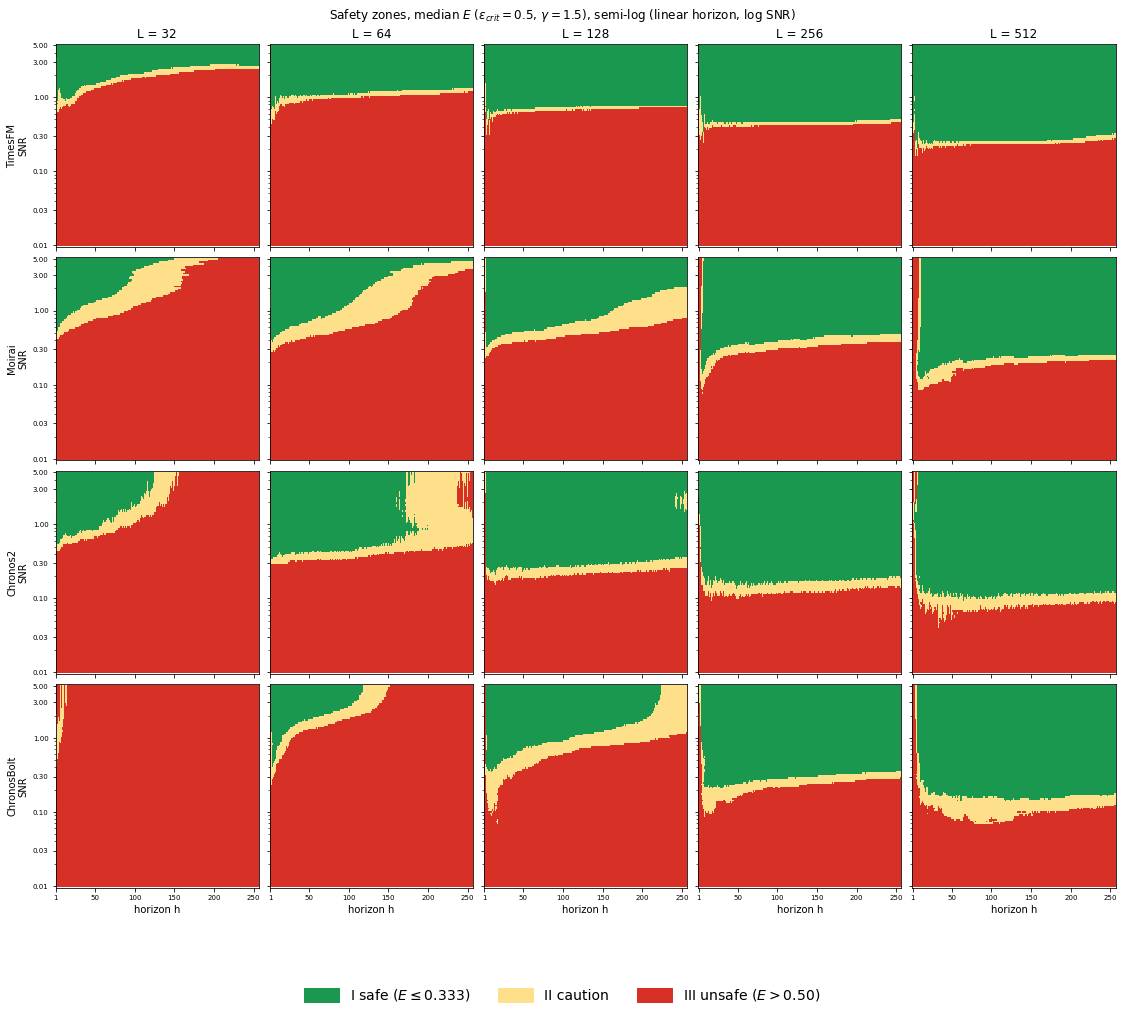

In [6]:
# Median plot, semi-log (linear horizon, log SNR)
fig, axes = plt.subplots(len(model_order), len(context_lengths),
                         figsize=(3.1 * len(context_lengths), 3.1 * len(model_order)),
                         sharex=True, sharey=True, constrained_layout=True, squeeze=False)
zones_used = []

for row, model_name in enumerate(model_order):
    for col, L in enumerate(context_lengths):
        part = E_table[(E_table["model"] == model_name) & (E_table["L"] == L)]
        zone_grid = part.pivot(index="snr", columns="horizon", values="zone_median")
        zone_grid = zone_grid.reindex(index=snr_values, columns=horizon_values).to_numpy().astype(float)
        zones_used += list(np.unique(zone_grid[np.isfinite(zone_grid)]))

        ax = axes[row, col]
        ax.pcolormesh(horizon_values, snr_values, np.ma.masked_invalid(zone_grid),
                      cmap=colormap, norm=color_steps, shading="nearest")
        ax.set_xscale("linear")
        ax.set_yscale("log")
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.yaxis.set_major_formatter(ScalarFormatter())
        ax.set_xticks([1, 50, 100, 150, 200, 250])
        ax.set_yticks([0.01, 0.03, 0.1, 0.3, 1, 3, 5])
        ax.set_xlim(horizon_values.min() - 0.5, horizon_values.max() + 0.5)
        ax.set_ylim(snr_values.min() * 0.95, snr_values.max() * 1.05)
        ax.tick_params(labelsize=7)
        if row == 0:
            ax.set_title(f"L = {L}")
        if col == 0:
            ax.set_ylabel(f"{model_labels[model_name]}\nSNR")
        if row == len(model_order) - 1:
            ax.set_xlabel("horizon h")

fig.suptitle(f"Safety zones, median $E$ ($\\epsilon_{{crit}}={eps_crit}$, $\\gamma={gamma}$), "
             f"semi-log (linear horizon, log SNR)", y=1.02)

# legend below the figure, only with the zones that occur
legend_boxes = []
for zone in range(4):
    if zone in zones_used:
        legend_boxes.append(plt.Rectangle((0, 0), 1, 1, color=zone_colors[zone], label=zone_names[zone]))
fig.legend(handles=legend_boxes, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.11),
           fontsize=legend_fontsize, handlelength=2.5, handleheight=1.2, columnspacing=2.0)

fig.savefig(f"{results_folder}/fig1_zones_median_semilog.png", dpi=200, bbox_inches="tight")
plt.show()

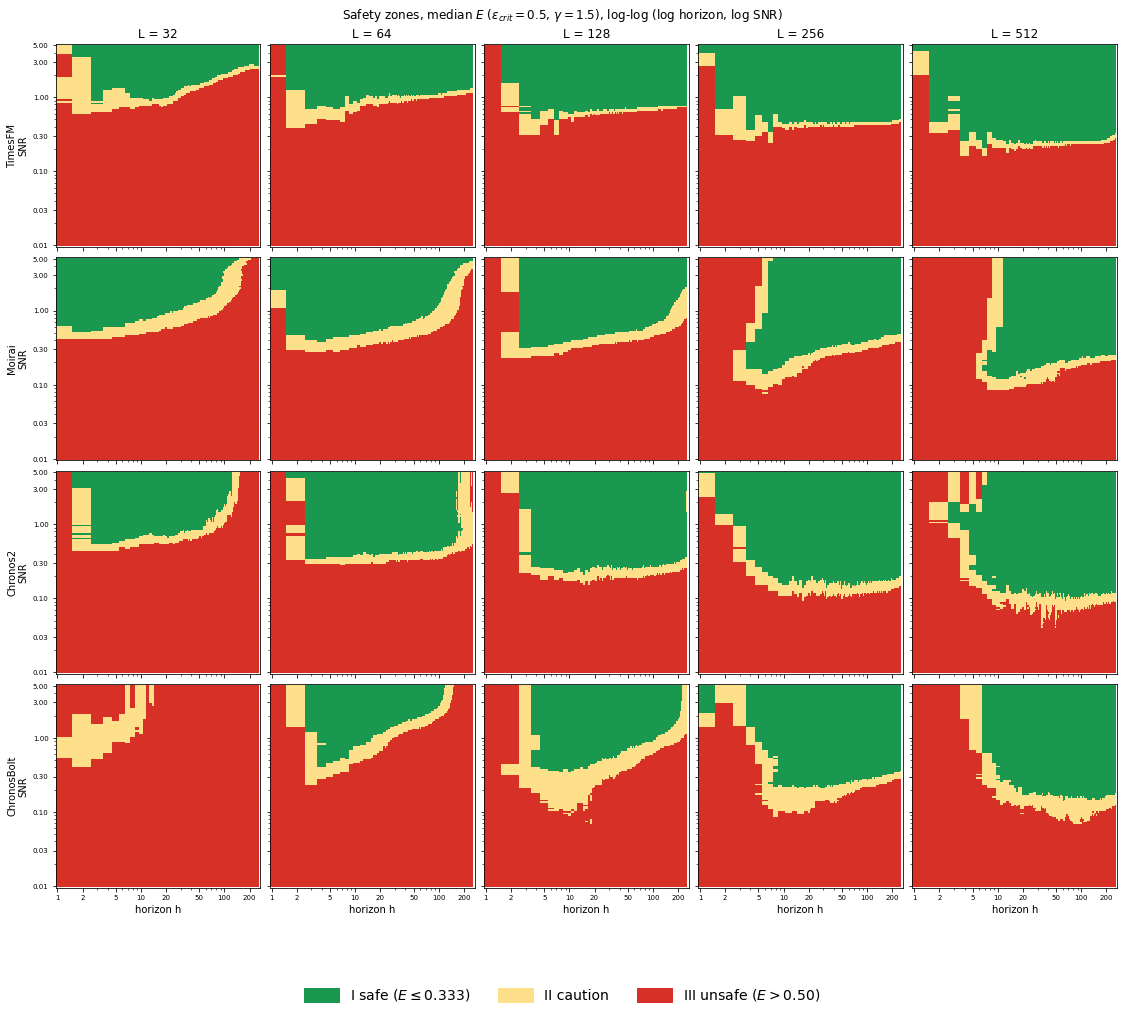

In [7]:
# Median plot, log-log (log horizon, log SNR)
fig, axes = plt.subplots(len(model_order), len(context_lengths),
                         figsize=(3.1 * len(context_lengths), 3.1 * len(model_order)),
                         sharex=True, sharey=True, constrained_layout=True, squeeze=False)
zones_used = []

for row, model_name in enumerate(model_order):
    for col, L in enumerate(context_lengths):
        part = E_table[(E_table["model"] == model_name) & (E_table["L"] == L)]
        zone_grid = part.pivot(index="snr", columns="horizon", values="zone_median")
        zone_grid = zone_grid.reindex(index=snr_values, columns=horizon_values).to_numpy().astype(float)
        zones_used += list(np.unique(zone_grid[np.isfinite(zone_grid)]))

        ax = axes[row, col]
        ax.pcolormesh(horizon_values, snr_values, np.ma.masked_invalid(zone_grid),
                      cmap=colormap, norm=color_steps, shading="nearest")
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.yaxis.set_major_formatter(ScalarFormatter())
        ax.set_xticks([1, 2, 5, 10, 20, 50, 100, 200])
        ax.set_yticks([0.01, 0.03, 0.1, 0.3, 1, 3, 5])
        ax.set_xlim(horizon_values.min() * 0.95, horizon_values.max() * 1.05)
        ax.set_ylim(snr_values.min() * 0.95, snr_values.max() * 1.05)
        ax.tick_params(labelsize=7)
        if row == 0:
            ax.set_title(f"L = {L}")
        if col == 0:
            ax.set_ylabel(f"{model_labels[model_name]}\nSNR")
        if row == len(model_order) - 1:
            ax.set_xlabel("horizon h")

fig.suptitle(f"Safety zones, median $E$ ($\\epsilon_{{crit}}={eps_crit}$, $\\gamma={gamma}$), "
             f"log-log (log horizon, log SNR)", y=1.02)

# legend below the figure, only with the zones that occur
legend_boxes = []
for zone in range(4):
    if zone in zones_used:
        legend_boxes.append(plt.Rectangle((0, 0), 1, 1, color=zone_colors[zone], label=zone_names[zone]))
fig.legend(handles=legend_boxes, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.11),
           fontsize=legend_fontsize, handlelength=2.5, handleheight=1.2, columnspacing=2.0)

fig.savefig(f"{results_folder}/fig1_zones_median_loglog.png", dpi=200, bbox_inches="tight")
plt.show()